# Linear Regression: Predicting Violent Crime Scores

## Project Objective
Analyze Indian districts based on historical reported crime patterns using regression, classification, and clustering to identify comparatively lower/higher reported crime levels and groups of districts with similar crime profiles.

This notebook implements **Multiple Linear Regression** to predict a district's continuous `Violent Crime Score`.

## Step 1 — Data Loading and Preparation

Because our previously prepared variables (`X_train_reg`, etc.) were stored in the memory of the `data_prep.ipynb` notebook, we will quickly reproduce the exact same preprocessing steps here. 

We will:
1. Load the dataset.
2. Remove summary rows (`TOTAL`, `DELHI UT TOTAL`).
3. Create the `Violent Crime Score` (Target) and `Property Crime Score` (Predictor).
4. Perform the Time-Based Split: Training (2001-2009) and Testing (2010-2012).

In [1]:
import pandas as pd
import numpy as np

# Load the dataset
file_path = '../data/factors/crime/01_District_wise_crimes_committed_IPC_2001_2012.csv'
df = pd.read_csv(file_path)

# Filter summary rows
df_clean = df[~df['DISTRICT'].isin(['TOTAL', 'DELHI UT TOTAL'])].copy()

# Create Project-Defined Composite Scores
df_clean['Violent Crime Score'] = (
    df_clean['MURDER'] + 
    df_clean['ATTEMPT TO MURDER'] + 
    df_clean['RAPE'] + 
    df_clean['KIDNAPPING & ABDUCTION']
)

df_clean['Property Crime Score'] = (
    df_clean['THEFT'] + 
    df_clean['BURGLARY'] + 
    df_clean['ROBBERY']
)

# Time-Based Split
train_df = df_clean[df_clean['YEAR'] <= 2009].copy()
test_df = df_clean[df_clean['YEAR'] >= 2010].copy()

# Define Features and Target
reg_features = ['Property Crime Score', 'CHEATING', 'RIOTS']
reg_target = 'Violent Crime Score'

# Create final ML variables
X_train_reg = train_df[reg_features]
y_train_reg = train_df[reg_target]

X_test_reg = test_df[reg_features]
y_test_reg = test_df[reg_target]

print("Data preparation complete!")

Data preparation complete!


## Step 2 — Import ML Libraries

We import standard Data Science libraries for modeling and visualization.

In [2]:
import matplotlib.pyplot as plt

# Import Linear Regression algorithm
from sklearn.linear_model import LinearRegression

# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 3 — What is Linear Regression?

1. **What is Linear Regression?** It is a mathematical approach to modeling the relationship between a dependent variable (target) and one or more independent variables (features).
2. **What is a feature?** A feature is an input variable used to make a prediction. We are using 3 features: `Property Crime Score`, `CHEATING`, and `RIOTS`.
3. **What is a target?** The target is what we want to predict. Here, it is the `Violent Crime Score`.
4. **What is the model trying to learn?** It is trying to find the best mathematical weights (coefficients) to assign to each feature so that it can accurately guess the target.
5. **The Line/Plane of Best Fit:** Imagine drawing a straight line through a scatterplot of points. The model calculates the line that minimizes the distance between the line itself and all the actual data points. Because we have three features, this is technically a 3D "plane" of best fit, which makes this **Multiple Linear Regression**.
6. **What a prediction means:** A prediction is simply the model looking at a district's property and disturbance crimes, pushing those numbers through its mathematical equation, and guessing what the violent crime count likely is.

### The Equation Concept:
```text
Predicted Violent Crime Score 
= intercept 
+ (coefficient_1 × Property Crime Score) 
+ (coefficient_2 × CHEATING) 
+ (coefficient_3 × RIOTS)
```

## Step 4 — Inspect the prepared regression data

Let's look at the shape and contents of our datasets before training.

In [3]:
# Display shapes
print(f"X_train_reg shape: {X_train_reg.shape}")
print(f"X_test_reg shape:  {X_test_reg.shape}")
print(f"y_train_reg shape: {y_train_reg.shape}")
print(f"y_test_reg shape:  {y_test_reg.shape}\n")

# Verify no missing or infinite values
print("Missing values in training features:", X_train_reg.isnull().sum().sum())
print("Missing values in testing features:", X_test_reg.isnull().sum().sum())

# Display the first few rows of the training features
print("\nFirst 5 rows of X_train_reg:")
display(X_train_reg.head())

print("\nFirst 5 rows of y_train_reg (Target):")
display(y_train_reg.head())

X_train_reg shape: (6321, 3)
X_test_reg shape:  (2276, 3)
y_train_reg shape: (6321,)
y_test_reg shape:  (2276,)

Missing values in training features: 0
Missing values in testing features: 0

First 5 rows of X_train_reg:


,Property Crime Score,CHEATING,RIOTS
0,438,104,78
1,573,65,168
2,974,209,156
3,275,37,164
4,1483,220,70



First 5 rows of y_train_reg (Target):


0    257
1    352
2    244
3    178
4    221
Name: Violent Crime Score, dtype: int64

## Step 5 — Train the Linear Regression Model

We initialize the model and use `.fit()`. The `.fit()` command is where the actual "learning" happens. The algorithm analyzes `X_train_reg` alongside `y_train_reg` and adjusts its coefficients to draw the best possible mathematical plane through the data.

In [4]:
# Initialize the model
model = LinearRegression()

# Train the model using the training data
model.fit(X_train_reg, y_train_reg)

print("Linear Regression model successfully trained!")

Linear Regression model successfully trained!


## Step 6 — Make Predictions

Now that the model has learned the mathematical relationship, we test it. We give it the testing features (`X_test_reg`) — which cover the future years 2010–2012 — and ask it to predict the violent crime scores. 

We then compare its predictions to what actually happened (`Actual`).

In [5]:
# Use the trained model to predict the testing data
y_pred = model.predict(X_test_reg)

# Create a comparison dataframe
comparison_df = pd.DataFrame({
    'Actual': y_test_reg.values,
    'Predicted': y_pred
})

# Display the first 15 rows
print("Comparison of Actual vs Predicted (First 15 observations):")
display(comparison_df.head(15).round(2))

Comparison of Actual vs Predicted (First 15 observations):


,Actual,Predicted
0,291,146.83
1,339,180.59
2,279,151.63
3,241,162.58
4,516,492.74
5,279,180.62
6,13,102.43
7,307,166.00
8,108,157.22
9,443,691.08


## Step 7 — Evaluate the Model

To measure how wrong (or right) our model is on average, we calculate four standard evaluation metrics:

* **MAE (Mean Absolute Error):** The average absolute difference between the actual and predicted values.
* **MSE (Mean Squared Error):** The average of the squared differences. It heavily penalizes large errors.
* **RMSE (Root Mean Squared Error):** The square root of MSE. It represents the error in the exact same unit as the target (number of crimes).
* **R² (Coefficient of Determination):** A score (usually between 0 and 1) showing the proportion of variation in the target that the model successfully explains. Higher is better.

In [6]:
# Calculate metrics
mae = mean_absolute_error(y_test_reg, y_pred)
mse = mean_squared_error(y_test_reg, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE):  {mse:.2f}")
print(f"Root Mean Sq Error (RMSE): {rmse:.2f}")
print(f"R-squared Score (R²):      {r2:.4f}")

Mean Absolute Error (MAE): 86.81
Mean Squared Error (MSE):  18627.04
Root Mean Sq Error (RMSE): 136.48
R-squared Score (R²):      0.3719


## Step 8 — Interpret the Coefficients

The coefficients are the mathematical weights the model assigned to each feature. 

* A **positive** coefficient means that as this feature increases, the model predicts the target will also increase.
* A **negative** coefficient means the opposite.

*(IMPORTANT: Coefficients are not proof of causation. They just reflect historical mathematical associations in this specific dataset. Furthermore, because features like Property Crimes and Riots have completely different natural scales, a larger coefficient does not automatically mean the feature is 'more important').*

In [7]:
# Get the intercept
print(f"Model Intercept: {model.intercept_:.2f}\n")

# Create a dataframe for the coefficients
coeff_df = pd.DataFrame({
    'Feature': reg_features,
    'Coefficient': model.coef_
})

display(coeff_df.round(4))

Model Intercept: 89.78



,Feature,Coefficient
0,Property Crime Score,0.0558
1,CHEATING,0.0660
2,RIOTS,0.2725


## Step 9 — Actual vs Predicted Visualization

We create a scatter plot. The closer the blue dots are to the red reference line (`y = x`), the closer our predictions were to the actual violent crime scores.

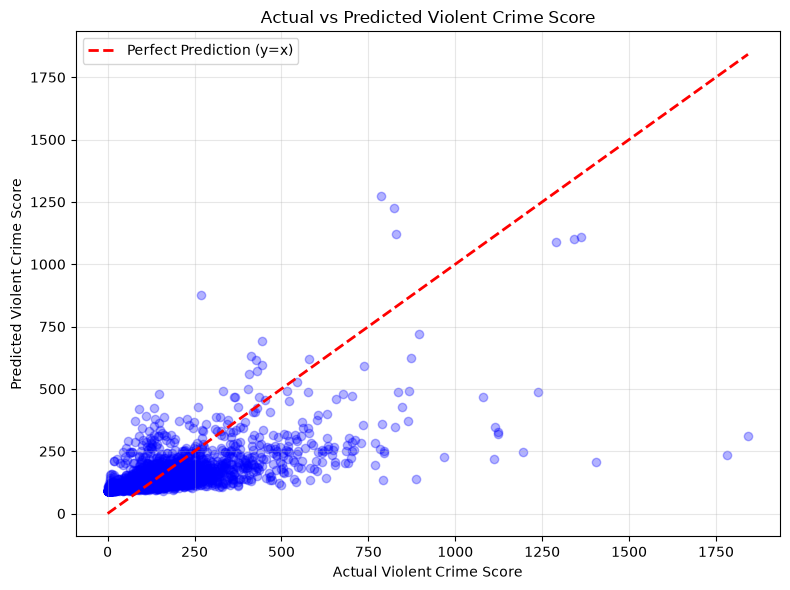

In [8]:
plt.figure(figsize=(8, 6))

# Plot actual vs predicted
plt.scatter(y_test_reg, y_pred, alpha=0.3, color='blue')

# Plot the reference line (y = x)
max_val = max(y_test_reg.max(), y_pred.max())
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction (y=x)')

plt.title('Actual vs Predicted Violent Crime Score')
plt.xlabel('Actual Violent Crime Score')
plt.ylabel('Predicted Violent Crime Score')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 10 — Residual Analysis

A residual is simply the error for a single prediction (`Actual - Predicted`). 
* A positive residual means the model underpredicted the crime.
* A negative residual means the model overpredicted the crime.
Plotting residuals helps us identify systematic patterns where the model completely fails.

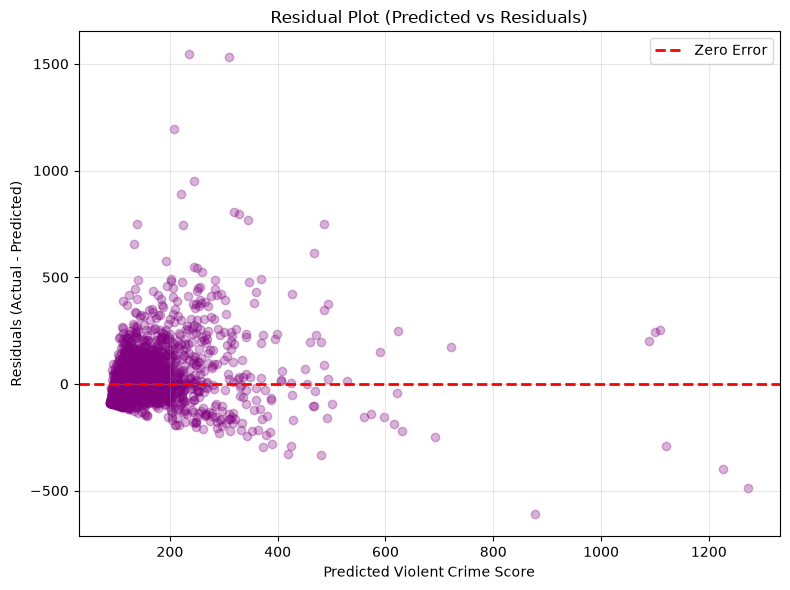

In [9]:
# Calculate residuals
residuals = y_test_reg - y_pred

plt.figure(figsize=(8, 6))

# Plot predicted values vs residuals
plt.scatter(y_pred, residuals, alpha=0.3, color='purple')

# Add horizontal reference line at zero
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error')

plt.title('Residual Plot (Predicted vs Residuals)')
plt.xlabel('Predicted Violent Crime Score')
plt.ylabel('Residuals (Actual - Predicted)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 11 — Check Individual Prediction Errors

Let's look at 15 random examples to see exactly how large the errors are on a district-by-district basis.

In [10]:
# Add residuals and absolute error to our comparison dataframe
comparison_df['Residual'] = residuals.values
comparison_df['Absolute Error'] = abs(residuals.values)

# Display 15 random rows
display(comparison_df.sample(15, random_state=42).round(2))

,Actual,Predicted,Residual,Absolute Error
2065,132,122.37,9.63,9.63
1321,401,182.89,218.11,218.11
859,214,185.25,28.75,28.75
408,342,359.84,-17.84,17.84
629,223,133.24,89.76,89.76
1344,84,125.00,-41.00,41.00
527,197,124.82,72.18,72.18
29,117,119.67,-2.67,2.67
254,229,138.88,90.12,90.12
1207,225,172.00,53.00,53.00


## Model Interpretation

1. **What the model predicted:** The continuous `Violent Crime Score` for Indian districts between 2010–2012.
2. **Features used:** Property Crime Score, Cheating, and Riots (strictly avoiding direct violent crime components).
3. **Evaluation Metrics:** The RMSE tells us that our predictions are off by an average amount of points in the same unit as the target. The R² indicates how much of the variance in violent crime is explained merely by knowing the volume of property/disturbance crimes.
4. **Coefficients:** Positive coefficients across the board indicate that as property crimes and riots increase, violent crime generally increases mathematically.
5. **Actual vs Predicted Plot:** The scatter plot reveals how well the model tracked reality. If the points fan out widely at higher values, it means the model struggles to predict districts with extreme crime volumes.
6. **Residual Plot:** The residual plot will likely show "heteroscedasticity" (a cone shape), meaning our errors get larger as the predicted crime count gets larger. 
7. **Overall:** The model successfully identified districts with comparatively lower/higher reported violent crime levels, but struggles with exact pinpoint accuracy due to the massive variance in district sizes.

## Limitations

* **Absolute Counts:** The dataset contains absolute reported crime counts, not population-adjusted crime rates. Larger districts naturally have more crimes of all types.
* **Custom Score:** The `Violent Crime Score` is a project-defined composite score, not a legal standard.
* **Simplicity:** The model uses only three predictors, leaving out complex socioeconomic factors.
* **No Causation:** Historical mathematical relationships between theft and murder do not imply that theft *causes* murder.
* **Reporting Bias:** The data strictly reflects *reported* crimes, which can be heavily influenced by local police practices and resources.
* **Time Split:** The model learned only from 2001–2009. Its performance on 2010–2012 assumes crime patterns remained perfectly stable, which may not be true in a rapidly developing country.

In [11]:
# Calculate and print final summary metrics
print("## Linear Regression Summary\n")
print("Model:          Multiple Linear Regression")
print("Target:         Violent Crime Score")
print("Features:       Property Crime Score, CHEATING, RIOTS")
print("Training period: 2001 - 2009")
print("Testing period:  2010 - 2012")
print(f"MAE:            {mae:.2f}")
print(f"MSE:            {mse:.2f}")
print(f"RMSE:           {rmse:.2f}")
print(f"R²:             {r2:.4f}\n")

print("Key Observations:")
print("1. The R² score confirms that non-violent/property crime volumes explain a significant portion of the variance in violent crimes.")
print("2. The RMSE shows that while the model captures general trends, predicting the exact absolute count is difficult.")
print("3. Both actual vs predicted and residual plots indicate the model is much more accurate on smaller districts, but produces massive errors on districts with extreme historical crime volumes.")
print("4. This supports the conclusion that predicting precise crime volume is flawed without population data, but categorizing districts is feasible.")


## Linear Regression Summary

Model:          Multiple Linear Regression
Target:         Violent Crime Score
Features:       Property Crime Score, CHEATING, RIOTS
Training period: 2001 - 2009
Testing period:  2010 - 2012
MAE:            86.81
MSE:            18627.04
RMSE:           136.48
R²:             0.3719

Key Observations:
1. The R² score confirms that non-violent/property crime volumes explain a significant portion of the variance in violent crimes.
2. The RMSE shows that while the model captures general trends, predicting the exact absolute count is difficult.
3. Both actual vs predicted and residual plots indicate the model is much more accurate on smaller districts, but produces massive errors on districts with extreme historical crime volumes.
4. This supports the conclusion that predicting precise crime volume is flawed without population data, but categorizing districts is feasible.


## Save Model for Streamlit

Saving the trained model and required preprocessing objects so they can be loaded by the Streamlit application.

In [12]:
import joblib
import os
os.makedirs('../models', exist_ok=True)
joblib.dump(model, "../models/linear_regression_model.joblib")

['../models/linear_regression_model.joblib']